## ML-07 — Baseline Action Score and Top-20 Review

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YosraHilmi/Fly-Rank-Internship/blob/main/work/notebooks/w04_baseline_score.ipynb?flush_cache=true)



Note on position (data check)

In Google's Search Console bulk export, positions are zero-based (0 = first result), and average position = SUM(sum_position) / SUM(impressions) + 1. The warehouse documentation does not say whether gsc_sum_position follows this convention, so I tested it.

Evidence: the raw ratio SUM(gsc_sum_position) / SUM(gsc_impressions) is below 1 for 2,735 of 176,738 pages (1.55%), with a minimum of 0.0, which is impossible if positions start at 1. Rows with gsc_sum_position = 0 have a median of 1 impression (other rows: 18), which fits a single impression shown in the first result.

Decision: average position = SUM(gsc_sum_position) / SUM(gsc_impressions) + 1, using all rows with impressions. After the fix there are 176,738 rows (one per page) and the minimum average position is 1.0. This is an inference from the data and from Google's documented convention, not a documented fact of this dataset.

# Signal checks

**Signal 1 — Belief: pages at better average positions earn a higher CTR, so a page should be compared with peers at a similar position, not with the whole catalog.
Table: CTR by position band for pages with at least 500 impressions in March 2026 (the cutoff is justified by signal 2). Band = floor of average position; band 20 = position 20 or higher. Median CTR gives each page equal weight; pooled CTR (total clicks / total impressions) weights pages by impressions. n is printed per band. CTR values are percentages.**

In [39]:

from google.colab import userdata
import duckdb

# Retrieve the actual token value
hf_token = userdata.get("HF_TOKEN")

# Connect to DuckDB
con = duckdb.connect()

# Create the Hugging Face secret using the actual token
con.execute("""
    CREATE SECRET hf_secret (
        TYPE huggingface,
        TOKEN $token
    )
""", {"token": hf_token})

# Query the dataset
rel = "hf://datasets/FlyRank/internship-warehouse"

result = con.execute(f"""
    SELECT COUNT(*)
    FROM read_parquet(
        '{rel}/fact_content_daily_performance/**/*.parquet'
    )
""").fetchone()

print("Total rows:", result[0])



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total rows: 78835655


In [40]:

# Cell 0 - Setup
MONTH = "2026-03"
base = f"{rel}/fact_content_daily_performance"
march_path = f"{base}/month={MONTH}/**/*.parquet"

con.execute(f"""
CREATE OR REPLACE SECRET hf_secret
(TYPE huggingface, TOKEN $token)
""", {"token": hf_token})

# Try the recursive March-only partition path first.
try:
    con.execute(f"""
    CREATE OR REPLACE VIEW fact_mar AS
    SELECT * FROM read_parquet(
        '{march_path}', hive_partitioning=true
    )
    """)
    print("Working fact pattern: March partition recursive glob")
except Exception as e:
    print("First fact pattern failed:", str(e)[:500])
    try:
        march_path = f"{base}/month={MONTH}/*.parquet"
        con.execute(f"""
        CREATE OR REPLACE VIEW fact_mar AS
        SELECT * FROM read_parquet(
            '{march_path}', hive_partitioning=true
        )
        """)
        print("Working fact pattern: March partition direct glob")
    except Exception as e2:
        print("Second fact pattern failed:", str(e2)[:500])
        raise RuntimeError("Could not read the March partition.")

# Try dim_content as a Parquet folder, then as a single Parquet file.
dim_folder = f"{rel}/dim_content/**/*.parquet"
try:
    con.execute(f"""
    CREATE OR REPLACE TABLE dim_content_v AS
    SELECT client_hash_id, content_hash_id, content_type,
           main_intent, is_published, is_deleted
    FROM read_parquet('{dim_folder}')
    """)
    print("Working dim_content pattern: folder Parquet files")
except Exception as e:
    print("First dim_content pattern failed:", str(e)[:500])
    dim_file = f"{rel}/dim_content.parquet"
    try:
        con.execute(f"""
        CREATE OR REPLACE TABLE dim_content_v AS
        SELECT client_hash_id, content_hash_id, content_type,
               main_intent, is_published, is_deleted
        FROM read_parquet('{dim_file}')
        """)
        print("Working dim_content pattern: single Parquet file")
    except Exception as e2:
        print("Second dim_content pattern failed:", str(e2)[:500])
        raise RuntimeError("Could not read dim_content.")

print("setup ok")


Working fact pattern: March partition recursive glob
First dim_content pattern failed: HTTP Error: HTTP GET error on 'https://huggingface.co/api/datasets/FlyRank/internship-warehouse/tree/main/dim_content' (HTTP 404)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Working dim_content pattern: single Parquet file
setup ok


In [41]:

# Create page_month_v3 from March 2026 GSC data.
# Keep all rows with gsc_data_available IS TRUE and positive impressions for position calculation.

con.execute("""
CREATE OR REPLACE TABLE page_month_v3 AS
SELECT
    f.client_hash_id,
    f.content_hash_id,
    SUM(f.gsc_impressions) AS total_impressions,
    SUM(f.gsc_clicks) AS total_clicks,
    100.0 * SUM(f.gsc_clicks)
        / NULLIF(SUM(f.gsc_impressions), 0) AS ctr,
    SUM(CASE WHEN f.gsc_impressions > 0
             THEN f.gsc_sum_position ELSE 0 END)
        / NULLIF(
            SUM(CASE WHEN f.gsc_impressions > 0
                     THEN f.gsc_impressions ELSE 0 END), 0
        ) + 1 AS avg_position,
    d.content_type,
    d.main_intent
FROM fact_mar f
LEFT JOIN dim_content_v d
    ON f.client_hash_id = d.client_hash_id
   AND f.content_hash_id = d.content_hash_id
WHERE f.gsc_data_available IS TRUE
GROUP BY
    f.client_hash_id,
    f.content_hash_id,
    d.content_type,
    d.main_intent
""")

print("page_month_v3 created successfully.")
print("Rows in page_month_v3:", con.execute(
    "SELECT COUNT(*) FROM page_month_v3"
).fetchone()[0])
print("Minimum average position:", con.execute(
    "SELECT MIN(avg_position) FROM page_month_v3"
).fetchone()[0])


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

page_month_v3 created successfully.
Rows in page_month_v3: 176738
Minimum average position: 1.0


In [42]:

# Compare page-level median CTR with pooled CTR by position band.
display(con.sql("""
WITH eligible AS (
    SELECT
        LEAST(FLOOR(avg_position), 20)::INTEGER AS position_band,
        total_impressions,
        total_clicks,
        ctr
    FROM page_month_v3
    WHERE total_impressions >= 500
      AND avg_position IS NOT NULL
),
band_stats AS (
    SELECT
        position_band,
        COUNT(*) AS n_pages,
        MEDIAN(ctr) AS median_ctr,
        100.0 * SUM(total_clicks)
            / NULLIF(SUM(total_impressions), 0) AS pooled_ctr,
        100.0 * COUNT(*) FILTER (WHERE total_clicks = 0)
            / NULLIF(COUNT(*), 0) AS pct_zero_clicks
    FROM eligible
    GROUP BY position_band
)
SELECT
    position_band,
    n_pages,
    median_ctr,
    pooled_ctr,
    pooled_ctr / NULLIF(median_ctr, 0) AS pooled_to_median_ratio,
    pct_zero_clicks
FROM band_stats
ORDER BY position_band
""").df())

print("CTR values are percentages. The ratio is NULL when median CTR is zero.")
print("Pooled CTR weights pages by impressions; median CTR gives each page equal weight.")


,position_band,n_pages,median_ctr,pooled_ctr,pooled_to_median_ratio,pct_zero_clicks
0,1,482,0.077550,0.117621,1.516710,35.477178
1,2,2383,0.210084,0.358162,1.704852,13.428452
2,3,5074,0.268414,0.416247,1.550766,9.006701
3,4,6570,0.264463,0.377184,1.426226,8.173516
4,5,6529,0.230499,0.321306,1.393959,9.771787
5,6,5440,0.199336,0.279956,1.404448,12.205882
6,7,5417,0.235710,0.320288,1.358822,13.513015
7,8,3543,0.176056,0.286771,1.628857,17.499294
8,9,2661,0.165221,0.272811,1.651186,19.203307
9,10,2139,0.171821,0.326326,1.899220,22.019635


CTR values are percentages. The ratio is NULL when median CTR is zero.
Pooled CTR weights pages by impressions; median CTR gives each page equal weight.


Observed: the median CTR peaks at positions 3-4 (about 0.27%), falls to about 0.17% across positions 8-19, and to 0.08% from position 20 (n = 11,903). The pooled CTR is almost flat between positions 6 and 19 (0.27%-0.38%), so position explains little in that range. The share of zero-click pages rises with position (8%-10% at positions 3-5, 21%-23% at positions 10-19, 29.7% from position 20). Band 1 is unexpectedly low (median 0.078%, pooled 0.118%, n = 482) even with at least 500 impressions, and three pages hold 21.1% of its impressions; the cause is not explained by this table.

Verdict: **MIXED**. CTR falls as position worsens, but weakly in the middle bands and not at the top. Expected CTR is therefore taken from this data (pooled CTR per band), not from a generic benchmark table.


---



**Signal 2 — Belief: pages with few impressions have an unreliable CTR (mostly zero clicks), so a minimum-volume rule is needed.
Table: impression band, n pages, share of pages with zero clicks, and median CTR (March 2026, all pages). CTR values are percentages.t**

In [43]:

# Group pages by total impressions.
display(con.sql("""
WITH bucketed AS (
    SELECT
        CASE
            WHEN total_impressions < 50 THEN '<50'
            WHEN total_impressions < 150 THEN '50-149'
            WHEN total_impressions < 500 THEN '150-499'
            WHEN total_impressions < 2000 THEN '500-1999'
            ELSE '2000+'
        END AS impression_band,
        CASE
            WHEN total_impressions < 50 THEN 1
            WHEN total_impressions < 150 THEN 2
            WHEN total_impressions < 500 THEN 3
            WHEN total_impressions < 2000 THEN 4
            ELSE 5
        END AS band_order,
        total_clicks,
        ctr
    FROM page_month_v3
)
SELECT
    impression_band,
    COUNT(*) AS n_pages,
    100.0 * COUNT(*) FILTER (WHERE total_clicks = 0)
        / NULLIF(COUNT(*), 0) AS pct_zero_clicks,
    MEDIAN(ctr) AS median_ctr
FROM bucketed
GROUP BY impression_band, band_order
ORDER BY band_order
""").df())

print("Zero-click percentage is the share of pages with total_clicks = 0.")
print("CTR values are percentages.")


,impression_band,n_pages,pct_zero_clicks,median_ctr
0,<50,60624,94.901359,0.000000
1,50-149,24140,83.570837,0.000000
2,150-499,30050,64.552413,0.000000
3,500-1999,32047,29.328798,0.155039
4,2000+,29877,4.675838,0.206954


Zero-click percentage is the share of pages with total_clicks = 0.
CTR values are percentages.


Observed: the share of pages with zero clicks falls steadily as volume rises: 94.9% (<50 impressions, n = 60,624), 83.6% (50-149, n = 24,140), 64.6% (150-499, n = 30,050), 29.3% (500-1,999, n = 32,047) and 4.7% (2,000+, n = 29,877). The median CTR is 0 up to 499 impressions and positive from 500 (0.155%). With a typical CTR near 0.2%, a page needs roughly 500 impressions to expect even one click (rough estimate), so zero clicks at low volume says little about the page itself.

Verdict: **CONFIRMED**. The rule uses a minimum of 500 impressions.


---



## 1. My rule and its reason codes

1. My rule and its reason codes

among pages with at least 500 impressions and an average position below 6 in March 2026, compare each page's CTR with the pooled CTR of pages in the same position band. If the page is below it, estimate the unclaimed clicks and rank pages by them. This is a deliberately simple baseline (position only).

- Eligible: total_impressions >= 500 (signal 2: zero-click pages fall from 64.6% at 150-499 impressions to 29.3% at 500-1,999) and average position below 6 (1-based); 21,038 of 176,738 pages (11.9%) pass.
- Expected CTR: pooled CTR of the page's position band = SUM(clicks) / SUM(impressions) x 100.
- Score = total_impressions x max(0, expected_ctr - actual_ctr) / 100 (estimated unclaimed clicks).
- Reason code: CTR_BELOW_POSITION_PEERS. Action label: SNIPPET_REVIEW (review the title and meta description).
- Confidence note: higher at 2,000+ impressions (4.7% zero-click pages), lower at 500-1,999.
- Not used: last_optimized_date and content_updated_date (they describe the export date, July 2026, not March 2026), and any product flags or Analytics columns.

In [44]:

# Count eligible pages.
display(con.sql("""
SELECT
    COUNT(*) FILTER (
        WHERE total_impressions >= 500
          AND avg_position < 6
    ) AS eligible_pages,
    COUNT(*) AS all_pages,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE total_impressions >= 500
              AND avg_position < 6
        ) / NULLIF(COUNT(*), 0),
        1
    ) AS eligible_pct
FROM page_month_v3
""").df())

print("Eligibility rule: total_impressions >= 500 and avg_position < 6.")



,eligible_pages,all_pages,eligible_pct
0,21038,176738,11.9


Eligibility rule: total_impressions >= 500 and avg_position < 6.


## 2. Build the ranked queue (writes the CSV)

*Code the score, rank everything, write work/outputs/baseline_action_score.csv.*

In [45]:

# Recalculate pooled CTR baselines using published, non-deleted pages only.

con.execute("""
CREATE OR REPLACE TABLE pooled_ctr_baseline AS
SELECT
    LEAST(FLOOR(p.avg_position), 20)::INTEGER AS position_band,
    COUNT(*) AS page_count,
    SUM(p.total_impressions) AS impressions_sum,
    SUM(p.total_clicks) AS clicks_sum,
    100.0 * SUM(p.total_clicks)
        / NULLIF(SUM(p.total_impressions), 0) AS expected_ctr
FROM page_month_v3 p
JOIN dim_content_v d
    ON p.client_hash_id = d.client_hash_id
   AND p.content_hash_id = d.content_hash_id
WHERE p.total_impressions >= 500
  AND p.avg_position < 6
  AND p.avg_position IS NOT NULL
  AND d.is_published IS TRUE
  AND d.is_deleted IS FALSE
GROUP BY position_band
""")

print("Filtered pooled CTR baseline rebuilt.")
print("Position bands:", con.execute(
    "SELECT COUNT(*) FROM pooled_ctr_baseline"
).fetchone()[0])


Filtered pooled CTR baseline rebuilt.
Position bands: 5


In [46]:

# Rebuild the content dimension with publication and deletion status.

dim_file = f"{rel}/dim_content.parquet"

con.execute(f"""
CREATE OR REPLACE TABLE dim_content_v AS
SELECT
    client_hash_id,
    content_hash_id,
    content_type,
    main_intent,
    content_updated_date,
    is_published,
    is_deleted
FROM read_parquet('{dim_file}')
""")

print("Content metadata updated.")
print("Rows:", con.execute(
    "SELECT COUNT(*) FROM dim_content_v"
).fetchone()[0])


Content metadata updated.
Rows: 519606


In [47]:

# Rebuild the hand rule-based opportunity scores with status filters.

con.execute("""
CREATE OR REPLACE TABLE baseline_action_score AS
WITH eligible_pages AS (
    SELECT
        p.content_hash_id,
        p.total_impressions,
        p.total_clicks,
        p.ctr,
        p.avg_position,
        LEAST(FLOOR(p.avg_position), 20)::INTEGER AS position_band,
        d.content_updated_date AS last_updated,
        d.content_type,
        d.main_intent
    FROM page_month_v3 p
    JOIN dim_content_v d
        ON p.client_hash_id = d.client_hash_id
       AND p.content_hash_id = d.content_hash_id
    WHERE p.total_impressions >= 500
      AND p.avg_position < 6
      AND p.avg_position IS NOT NULL
      AND d.is_published IS TRUE
      AND d.is_deleted IS FALSE
),
scored AS (
    SELECT
        p.content_hash_id,
        p.total_impressions,
        p.total_clicks,
        p.ctr AS actual_ctr_pct,
        p.avg_position,
        p.position_band,
        b.expected_ctr AS expected_ctr_pct,
        b.expected_ctr - p.ctr AS ctr_gap_pp,
        GREATEST(b.expected_ctr - p.ctr, 0)
            * p.total_impressions / 100.0
            AS estimated_extra_clicks,
        p.last_updated,
        p.content_type,
        p.main_intent
    FROM eligible_pages p
    JOIN pooled_ctr_baseline b
        USING (position_band)
)
SELECT
    ROW_NUMBER() OVER (
        ORDER BY estimated_extra_clicks DESC,
                 total_impressions DESC
    ) AS opportunity_rank,
    *
FROM scored
""")

print("Filtered opportunity scores rebuilt.")
print("Scored pages:", con.execute(
    "SELECT COUNT(*) FROM baseline_action_score"
).fetchone()[0])


Filtered opportunity scores rebuilt.
Scored pages: 21034


In [48]:


# Review the highest-priority published, non-deleted pages.

display(con.sql("""
SELECT
    opportunity_rank,
    content_hash_id,
    last_updated,
    content_type,
    main_intent,
    position_band,
    total_impressions,
    total_clicks,
    ROUND(actual_ctr_pct, 6) AS actual_ctr_pct,
    ROUND(expected_ctr_pct, 6) AS expected_ctr_pct,
    ROUND(ctr_gap_pp, 6) AS ctr_gap_pp,
    ROUND(estimated_extra_clicks, 2) AS estimated_extra_clicks
FROM baseline_action_score
ORDER BY opportunity_rank
LIMIT 20
""").df())

print("All scored pages passed the publication and deletion filters.")
print("No client identifiers are included in this output.")



,opportunity_rank,content_hash_id,last_updated,content_type,main_intent,position_band,total_impressions,total_clicks,actual_ctr_pct,expected_ctr_pct,ctr_gap_pp,estimated_extra_clicks
0,1,content_8e1334d6356668e3,2026-06-22,keyword article,commercial,3,134984.0,1.0,0.000741,0.416151,0.415410,560.74
1,2,content_8d7d99f109e19aa2,2026-06-12,keyword article,informational,3,203497.0,289.0,0.142017,0.416151,0.274134,557.85
2,3,content_34a70fea29d15f24,2026-07-04,keyword article,informational,4,143019.0,43.0,0.030066,0.377184,0.347118,496.44
3,4,content_acbcc847f8996314,2026-07-03,keyword article,transactional,4,170808.0,262.0,0.153389,0.377184,0.223795,382.26
4,5,content_9ef3d7516483e665,2026-06-12,keyword article,informational,3,89229.0,92.0,0.103105,0.416151,0.313045,279.33
5,6,content_b99ea6861864dea5,2026-07-03,keyword article,informational,5,194337.0,361.0,0.185760,0.321231,0.135472,263.27
6,7,content_306bc78dff1eb683,2026-06-22,keyword article,informational,2,80821.0,35.0,0.043306,0.358187,0.314882,254.49
7,8,content_77276ad7a26f4905,2026-06-22,keyword article,informational,4,116707.0,200.0,0.171369,0.377184,0.205814,240.20
8,9,content_fc67675904376267,2026-07-05,keyword article,commercial,3,60172.0,18.0,0.029914,0.416151,0.386237,232.41
9,10,content_f352b7cfd0b2f434,2026-07-03,keyword article,transactional,4,136098.0,287.0,0.210877,0.377184,0.166306,226.34


All scored pages passed the publication and deletion filters.
No client identifiers are included in this output.


In [49]:

# Export the updated opportunity scores.

con.execute("""
COPY (
    SELECT *
    FROM baseline_action_score
    ORDER BY opportunity_rank
)
TO 'work/outputs/baseline_action_score.csv'
(HEADER, DELIMITER ',')
""")

print("Updated CSV exported to work/outputs/baseline_action_score.csv")
print("Exported rows:", con.execute(
    "SELECT COUNT(*) FROM baseline_action_score"
).fetchone()[0])


Updated CSV exported to work/outputs/baseline_action_score.csv
Exported rows: 21034


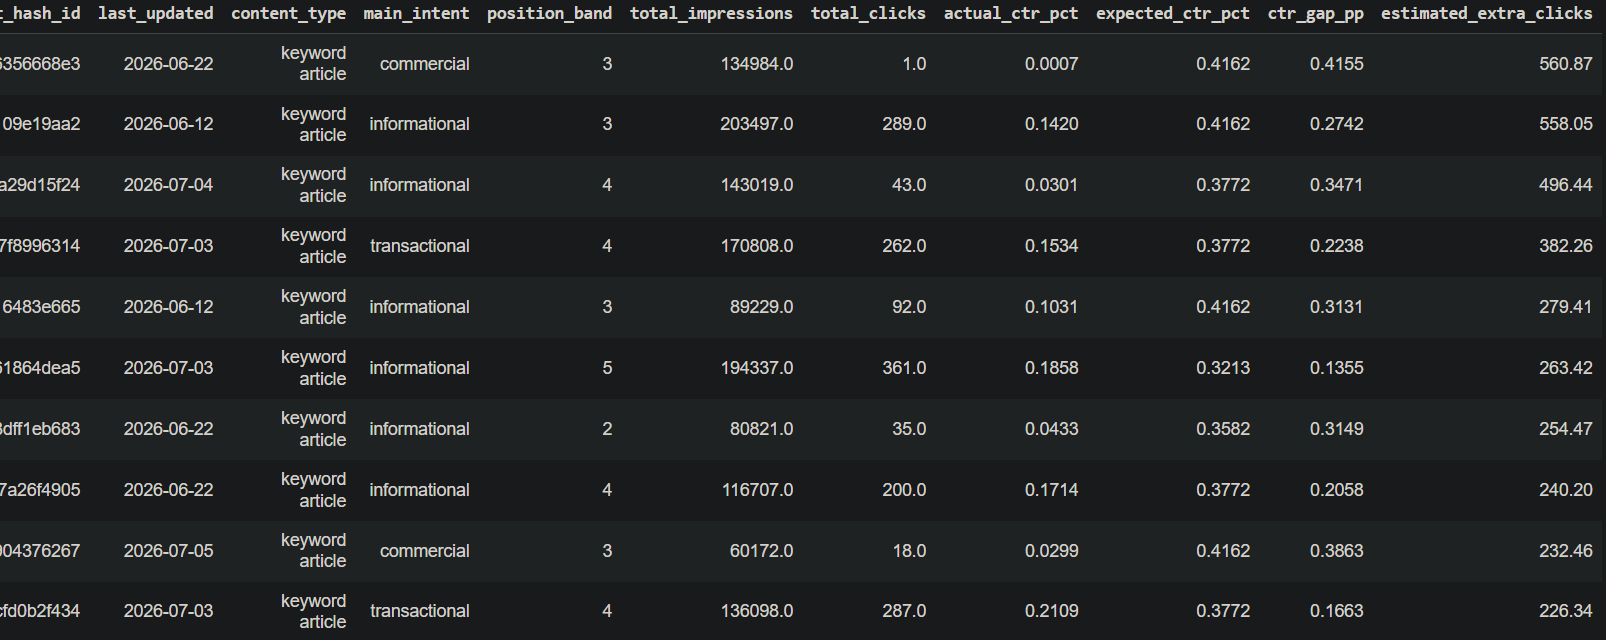

## 3. Top-10 review

| # | Page | Action | Reason code | Conf. | Why here | Wrong if |
|---|------|--------|-------------|-------|----------|----------|
| 1 | 8e1334d6 | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.0007% vs 0.416%; ~561 clicks | page deleted/unpublished or a data issue (not yet checked) |
| 2 | 8d7d99f1 | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.142% vs 0.416%; ~558 clicks | avg position blends queries; top queries may rank differently |
| 3 | 34a70fea | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.030% vs 0.377%; ~496 clicks | an answer box above it takes the clicks (not in data) |
| 4 | acbcc847 | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.153% vs 0.377%; ~382 clicks | ads above this transactional result (not in data) |
| 5 | 9ef3d751 | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.103% vs 0.416%; ~279 clicks | updated 2026-06-12, after March; snippet may have changed |
| 6 | b99ea686 | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.186% vs 0.321%; ~263 clicks | small gap; band median page earns 0.230%, so it is near typical |
| 7 | 306bc78d | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.043% vs 0.358%; ~254 clicks | March may be a seasonal low for its topic |
| 8 | 77276ad7 | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.171% vs 0.377%; ~240 clicks | near the band's median page (0.264%), not clearly weak |
| 9 | fc676759 | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.030% vs 0.416%; ~232 clicks | ads above this commercial result (not in data) |
| 10 | f352b7cf | SNIPPET_REVIEW | CTR_BELOW_POSITION_PEERS | high | CTR 0.211% vs 0.377%; ~226 clicks | close to the band's median page (0.264%) |

## 4. Weak picks + leakage check

*Which picks look wrong and why? Confirm no product flags or future windows leaked in.*

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.